In [1]:
#Jonathan Borowsky
#Grabe lab
#01/28/26

#rotamer calculation for collaboration with Rutter lab
#this notebook was used to develop the contents of x01_threonine_rotamers.py

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
#import compute_observable_on_trjs_x01_v3

In [36]:
#-------------------------------- select residues -------------------------------

whichprotein = "aac1"
whichresidue = "val"

location_type_info = [
    "on a helix facing the membrane core",
    "on a helix facing water or headgroups",
    "on a helix N terminal with no helix carbonyl to hydrogen bond with (variable solvation)",
    "on a loop (all of these are in water)"
]

#note that these are the residue numbers; which are one larger than the indices
threonines_ucp1 = [[193, 189, 121, 30, 122, 35],[226, 103, 97, 237, 259, 165, 166, 67, 62],[176, 177, 170, 156, 133, 60, 264],[11, 48, 108, 154]]
threonines_aac1 = [[23,125,161,196,218,232],[83,138,220],[253],[154,251]]
serines_ucp1 = [[18, 86, 89, 217, 279],[87, 183, 229],[114, 230, 273],[49, 50, 75, 111, 144, 242, 249, 296, 298]]
serines_aac1 = [[],[21, 118, 126, 166, 227],[6,68,179,212,275],[1,41,45,241]]
valines_ucp1 = [[282, 286, 216, 192, 184, 125, 127, 98, 28, 136, 235, 257, 64, 65],[38, 42, 138, 135, 202, 234],[211, 14, 271, 57, 232, 250],[51]]
valines_aac1 = [[16, 31, 37, 57, 77, 180, 193, 219, 222, 226, 233, 277, 286],[25, 58, 130, 288],[178, 211, 254],[102, 144, 207, 297]]

if whichresidue == "thr":
    if whichprotein == "aac1":
        residues_byloc = threonines_aac1
        offset = 1
    elif whichprotein == "ucp1":
        residues_byloc = threonines_ucp1
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        # return 0
    
elif whichresidue == "ser":
    if whichprotein == "aac1":
        residues_byloc = serines_aac1
        offset = 1
    elif whichprotein == "ucp1":
        residues_byloc = serines_ucp1
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        # return 0

elif whichresidue == "val":
    if whichprotein == "aac1":
        residues_byloc = valines_aac1
        offset = 1
    elif whichprotein == "ucp1":
        residues_byloc = valines_ucp1
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        # return 0

else:
    print(f"invalid protein {whichresidue}")
    # return 0  

#if residues_byloc == []:
    # return 0

#get residue indices matching mdanalysis object (0-indexed rather than using the PDB numbering)
residue_inds_byloc = [[ii-offset for ii in i] for i in residues_byloc]

#determine array dimensions necessary to encode residues in all location types in a single rectilinear numpy array
# this array is padded with values of 400 (outside the angle range returned by the dihedral calculation) 
# where there are not enough residues in a particular location type
n_loctypes = len(residues_byloc)
n_resis_per_loctype = max(len(lst) for lst in residues_byloc)

In [37]:
#-------------------------------- load trajectory -------------------------------

toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/seg_0035.gro"
trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
u = mda.Universe(toppath, trjpath)
protein_trj = u.select_atoms('protein')

n_frames = len(u.trajectory)

In [38]:
#                             CONSISTENCY TESTS

#---------------------------------------------------------------------------------------
#print pymol query for visual verification of correct residue assignment

colors = ["o","y","c","w"]

cmd = f"hide everything; show cart, poly; show sticks, poly and not elem h; show spheres, resn {whichresidue} and not elem H; util.cbag; util.cbam resn {whichresidue}; "

for c, s in zip(colors, residues_byloc):
    if len(s) > 0:
        cmd += f'util.cba{c} resi ' + "+".join([str(i) for i in s]) + "; "

print(cmd)

#---------------------------------------------------------------------------------------
#verify consistency of residues to be analyzed and input structure

flat_resis = np.array([si for s in residue_inds_byloc for si in s])
flat_resis.flatten()

#check for duplicated residue assignments
duplicates = (len(flat_resis) != len(np.unique(flat_resis)))
if duplicates:
    print("error: residue list includes residues multiple times")

#check for residue indices corresponding to the wrong residue
all_correct_resn = np.all([res.resname == whichresidue.upper() for res in protein_trj.residues[flat_resis]])
if not all_correct_resn:
    print(f"error: residue list contains residues other than {whichresidue}")

#check of missing residue assignments
total_resis = len([res.resname for res in protein_trj.residues if res.resname.lower() == whichresidue])
if total_resis > len(np.unique(flat_resis)):
    print(f"error: not all {whichresidue} residues are listed")
elif total_resis < len(np.unique(flat_resis)):
    print(f"error: more residues are listed than exist in the protein")    


hide everything; show cart, poly; show sticks, poly and not elem h; show spheres, resn val and not elem H; util.cbag; util.cbam resn val; util.cbao resi 16+31+37+57+77+180+193+219+222+226+233+277+286; util.cbay resi 25+58+130+288; util.cbac resi 178+211+254; util.cbaw resi 102+144+207+297; 


In [6]:
#for debugging
# thr_inds = threonine_inds_byloc[0]
# for r in protein_trj.residues[thr_inds]:
#     print(r)

In [7]:
#-------------------------------- calculate dihedrals -------------------------------

#array to hold results for all threonines 
#of shape [number of location types, maximum number of residues at any one location type, number of frames]
angles_all = np.ones((n_loctypes, n_resis_per_loctype, n_frames))*400
print(angles_all.shape)

for loc_ind in range(n_loctypes):
    resi_inds = residue_inds_byloc[loc_ind]
    #see https://userguide.mdanalysis.org/1.1.1/examples/analysis/structure/dihedrals.html
    chi1_atoms = [res.chi1_selection() for res in protein_trj.residues[resi_inds]]
    chi1_dihedrals = dihedrals.Dihedral(chi1_atoms).run()
    dihedral_angles = chi1_dihedrals.results.angles
    angles_all[loc_ind, 0:len(resi_inds)] = dihedral_angles.transpose()


(4, 9, 284)


In [8]:
#-------------------------------- digitize trajectory and calculate rotamer frequencies for each residue -------------------------------
#discretize trajectory

#mapping: 
#        a <= -120 : 0
# -120 < a <=    0 : 1
#    0 < a <=  120 : 2
#  120 < a <=  180 : 3
#  180 < a         : 4 #used to represent empty array entries (i.e. at location types with fewer residues)
angles_discrete = np.digitize(angles_all, [-120, 0, 120, 180], right=True) #this splits the rotamer centered on +-180 degrees into two bins
angles_discrete = np.where(angles_discrete == 3, 0, angles_discrete) #merge the bins for the rotamer at 180 degrees back together

#count occurrences of each rotamer
# note that due to trajectory length variability frequencies are not to be calculated until later
n_rotamers = 3
rotamer_counts = np.zeros((n_loctypes, n_resis_per_loctype, n_rotamers))

for rotamer_ind in range(n_rotamers):
    rotamers_onehot = np.where(angles_discrete == rotamer_ind, 1, 0)
    rotamer_counts[:,:,rotamer_ind] = np.sum(rotamers_onehot, axis = 2)
print(rotamer_counts)

[[[  0. 258.  26.]
  [  0. 281.   3.]
  [  0. 278.   6.]
  [  0.   0. 284.]
  [ 23. 130. 131.]
  [  0. 284.   0.]
  [  0.   0.   0.]
  [  0.   0.   0.]
  [  0.   0.   0.]]

 [[  1. 283.   0.]
  [  0.   0. 284.]
  [ 96. 182.   6.]
  [  0. 284.   0.]
  [  0. 115. 169.]
  [ 65. 188.  31.]
  [  0.   5. 279.]
  [  0.   0. 284.]
  [ 22. 260.   2.]]

 [[  5. 273.   6.]
  [  0. 261.  23.]
  [  0.   0. 284.]
  [  0. 284.   0.]
  [  0.   0. 284.]
  [  0. 284.   0.]
  [  1. 114. 169.]
  [  0.   0.   0.]
  [  0.   0.   0.]]

 [[ 51.   1. 232.]
  [ 11.   7. 266.]
  [263.   7.  14.]
  [ 27.   6. 251.]
  [  0.   0.   0.]
  [  0.   0.   0.]
  [  0.   0.   0.]
  [  0.   0.   0.]
  [  0.   0.   0.]]]


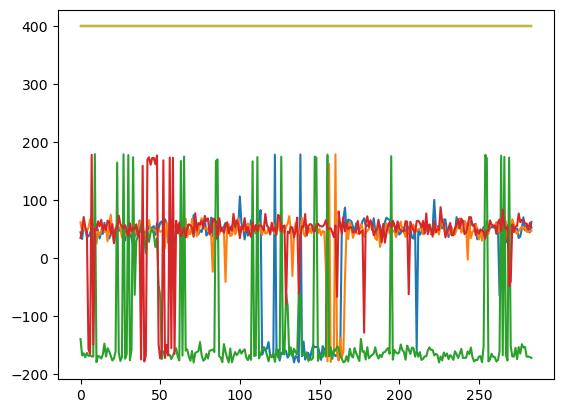

In [9]:
for i in angles_all[3]:
    plt.plot(i)

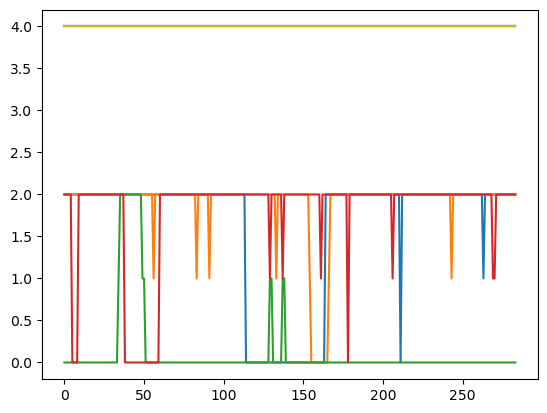

In [10]:
for i in angles_discrete[3]:
    plt.plot(i)

In [11]:
######################################################################################################
#                                               FIN
######################################################################################################